# Rule trends

## Setup

In [1]:
from pathlib import Path
import sys

ROOT = next(
    folder for folder in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
    if (folder / "result_summary" / "data_helper.py").exists()
)
sys.path[:0] = [
    str(ROOT / "result_summary"),
    str(ROOT / "result_summary" / "differential_rules" / "scripts"),
]

import final_figures_vis as fv
import rule_trends_helper as rt

In [2]:
FONT_SIZE = 20
CELL = 0.9
SQUARE = 0.6
TREND = 2.5

## Data

In [3]:
df_cells, df_fovs, rules, has_rule = rt.load()

Dropped 21 FOVs: Control_S
Loaded 598093 cells; FOVs: 267, biopsies: 73, patients: 71
Read results_CN_pairwise.csv
Loaded 15660 rules.
Kept 6978 rules at FDR <= 0.05.
Kept 6946 rules naming no Unidentified.
Kept 6946 rules (max_items=2, kind=None).


## Keys

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\keys\prevalence_FOV.pdf


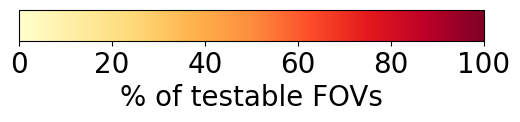

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\keys\rule_classes.pdf


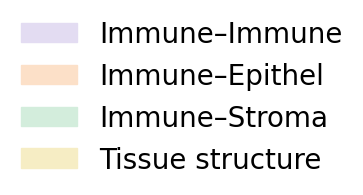

In [4]:
fv.save_prevalence_key(rt.LEVEL, FONT_SIZE)
fv.save_class_key(FONT_SIZE)

## Tests

In [5]:
results = rt.all_results(df_fovs, has_rule)

In [6]:
rt.summary(results)

tested passed
level                                              FOV    FOV
organ    trend                         kind                  
Colon    Clinical score                attracts     35      5
                                       avoids       16      2
         Cortico Response              attracts     17      0
                                       avoids        7      0
         Days after Transplant grouped attracts     23      6
                                       avoids        8      2
         GI stage                      attracts     11      0
                                       avoids        8      3
         Pathological score            attracts     28      5
                                       avoids       12      0
         Pathological stage            attracts     30      0
                                       avoids       11      3
Duodenum Clinical score                attracts     17      0
                                       avoids       12      0
         Cortico Response              attracts     25      1
                                       avoids       11      0
         Days after Transplant grouped attracts     18      2
                                       avoids        1      0
         GI stage                      attracts      5      0
                                       avoids        0      0
         Pathological score            attracts     11      0
                                       avoids        7      0
         Pathological stage            attracts      8      1
                                       avoids        0      0

## Figures

In [7]:
def rule_trends(changing):
    """The rule trend figures at `rt.LEVEL`, one per organ and trend: its changing rules, with FDR, or
    its stable ones."""
    pick, save = (rt.changed, "rule_trends") if changing else (rt.stable, "stable_rules")
    for title, blocks in rt.panels_for(results, rt.LEVEL, pick, changing, rt.MAX_RULES, df_cells).items():
        fv.plot_rule_trend(title, blocks, font_size=FONT_SIZE, cell=CELL, square=SQUARE, trend=TREND,
                           extra_text=changing and title == "Colon | Clinical score", save=f"{save}_{rt.LEVEL}")

### Changing rules

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_trends_FOV\Colon_Pathological_score.pdf
saved Colon_Pathological_score_1 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_trends_FOV


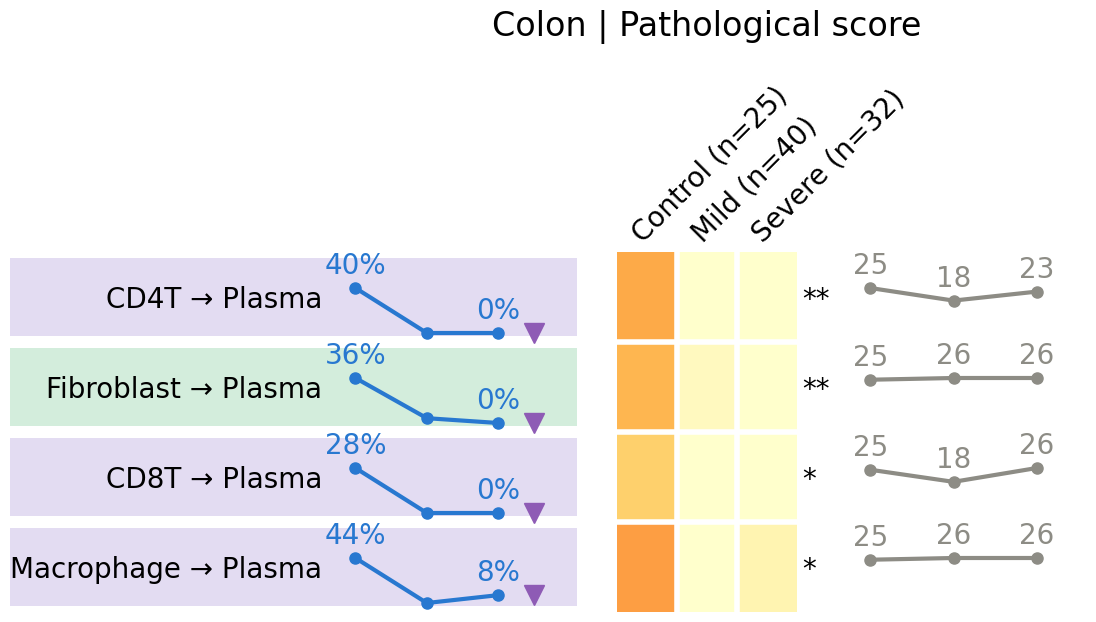

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_trends_FOV\Colon_Clinical_score.pdf
saved Colon_Clinical_score_1, Colon_Clinical_score_2 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_trends_FOV


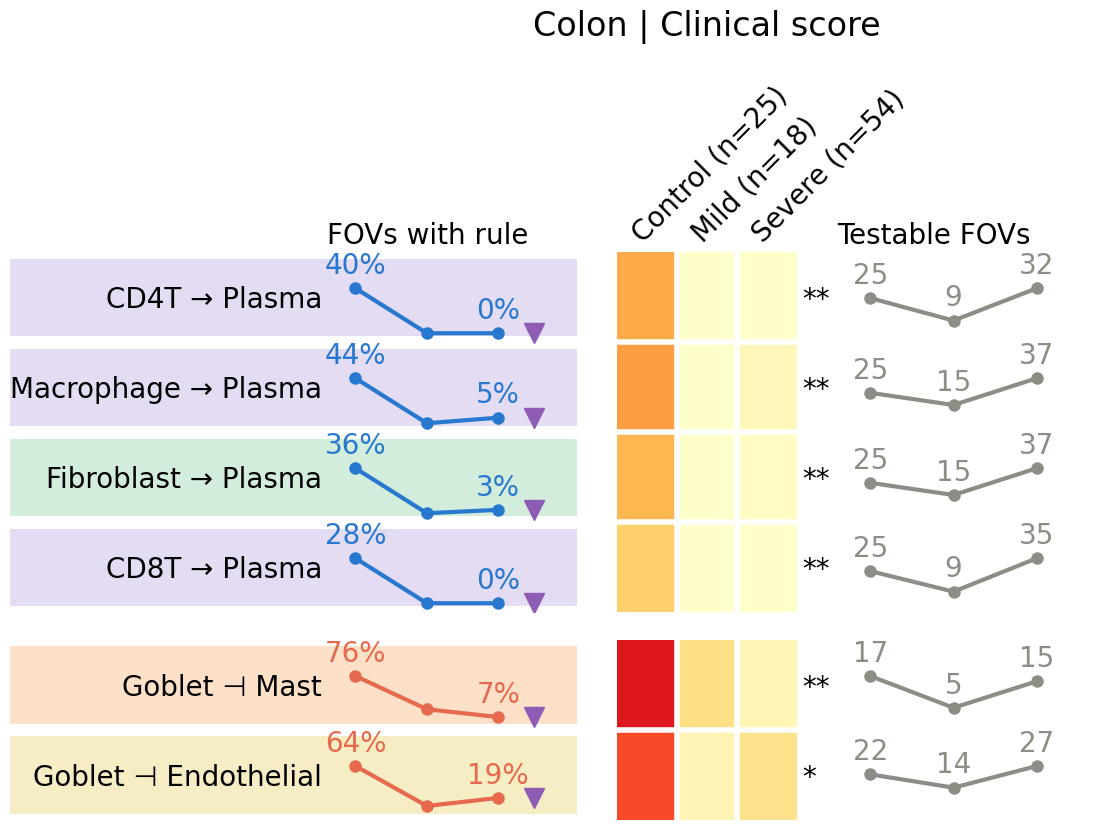

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_trends_FOV\Colon_Pathological_stage.pdf
saved Colon_Pathological_stage_1 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_trends_FOV


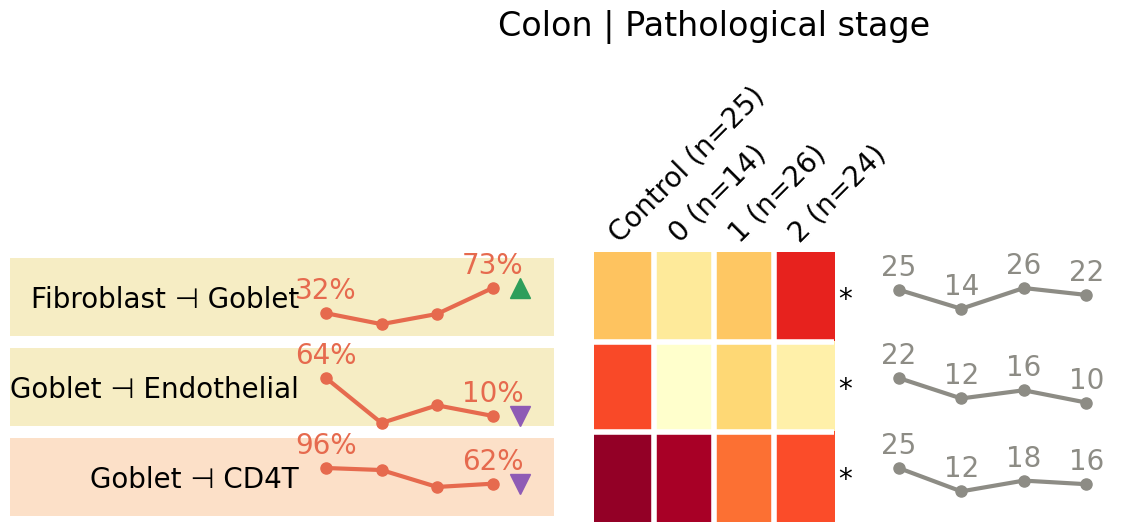

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_trends_FOV\Colon_GI_stage.pdf
saved Colon_GI_stage_1 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_trends_FOV


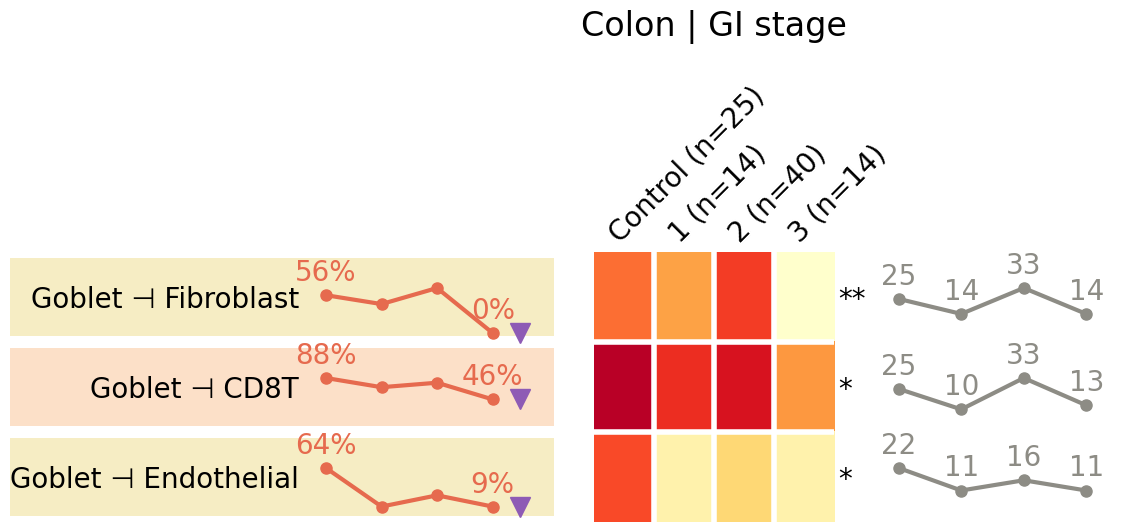

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_trends_FOV\Colon_Days_after_transplantation.pdf
saved Colon_Days_after_transplantation_1, Colon_Days_after_transplantation_2 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_trends_FOV


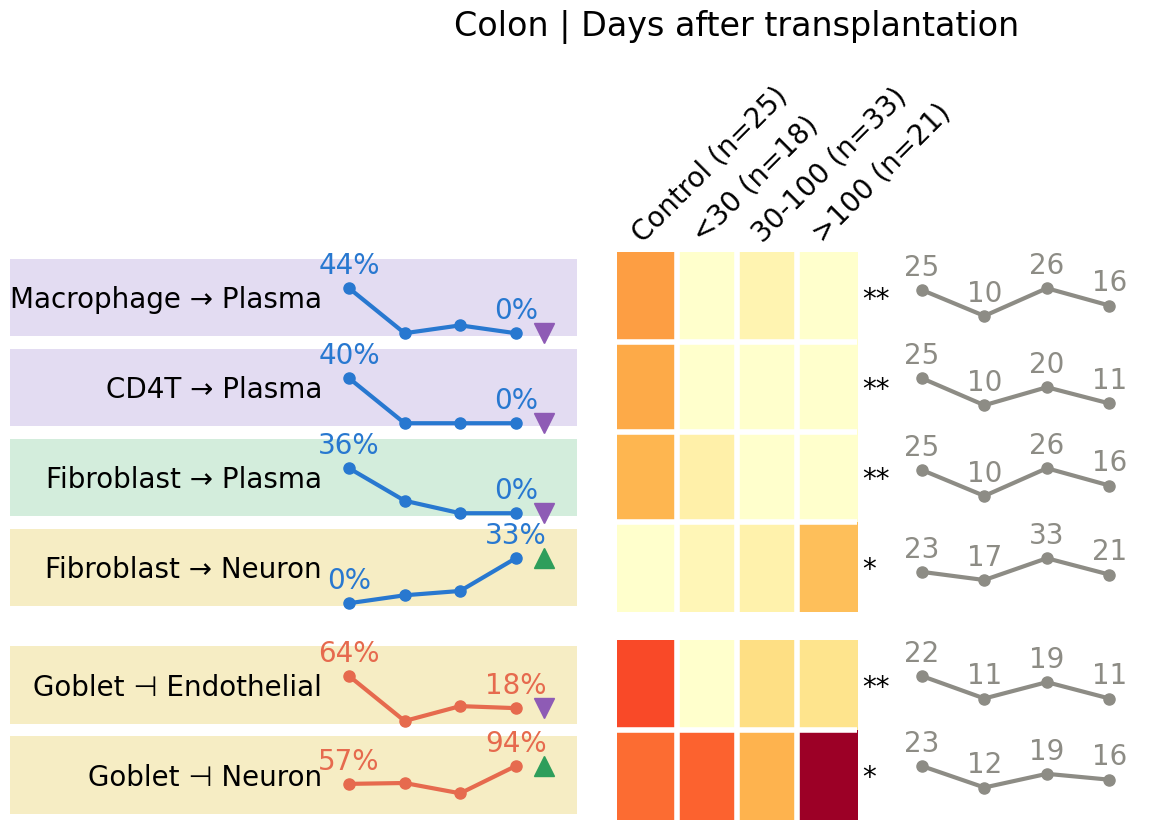

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_trends_FOV\Duodenum_Pathological_stage.pdf
saved Duodenum_Pathological_stage_1 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_trends_FOV


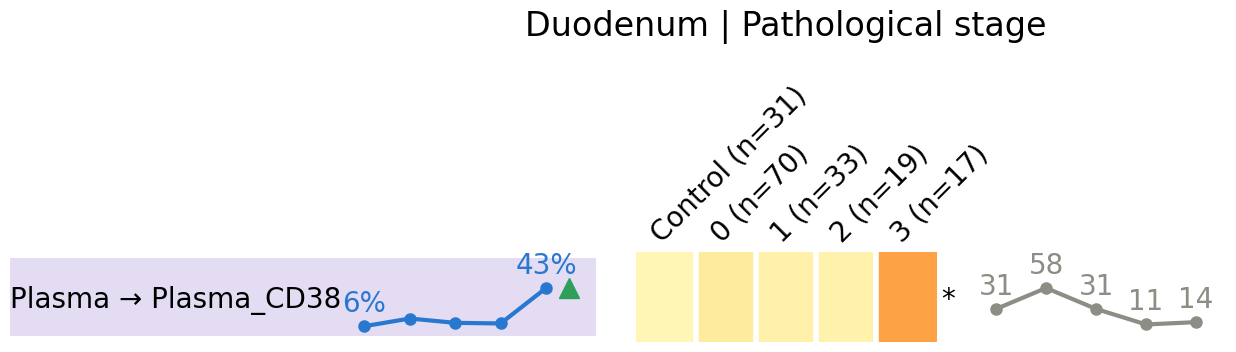

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_trends_FOV\Duodenum_Cortico_Response.pdf
saved Duodenum_Cortico_Response_1 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_trends_FOV


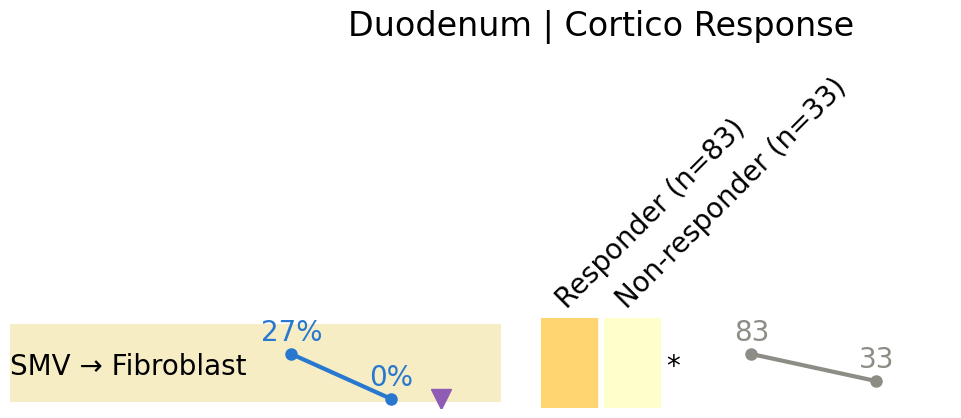

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_trends_FOV\Duodenum_Days_after_transplantation.pdf
saved Duodenum_Days_after_transplantation_1 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_trends_FOV


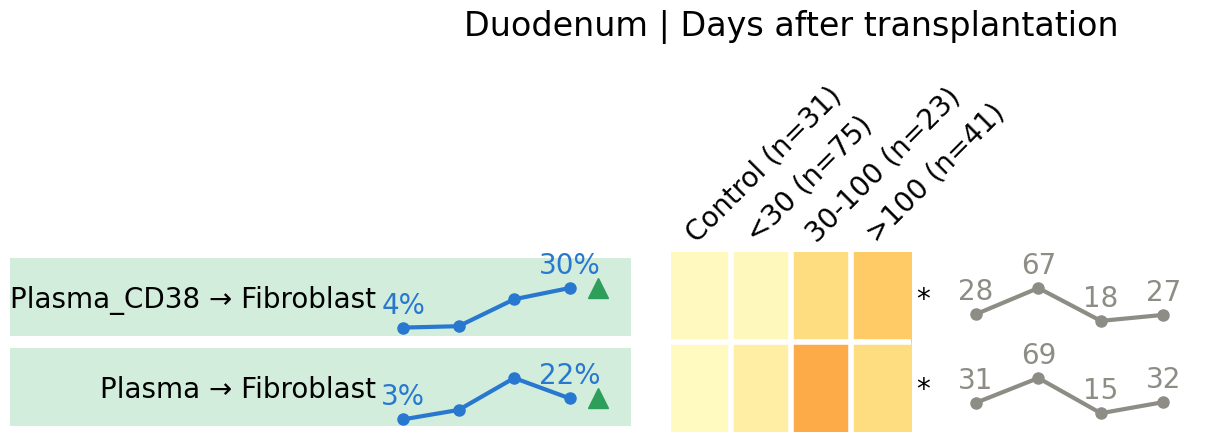

In [8]:
rule_trends(changing=True)

### Stable rules

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\stable_rules_FOV\Colon_Pathological_score.pdf
saved Colon_Pathological_score_1 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\stable_rules_FOV


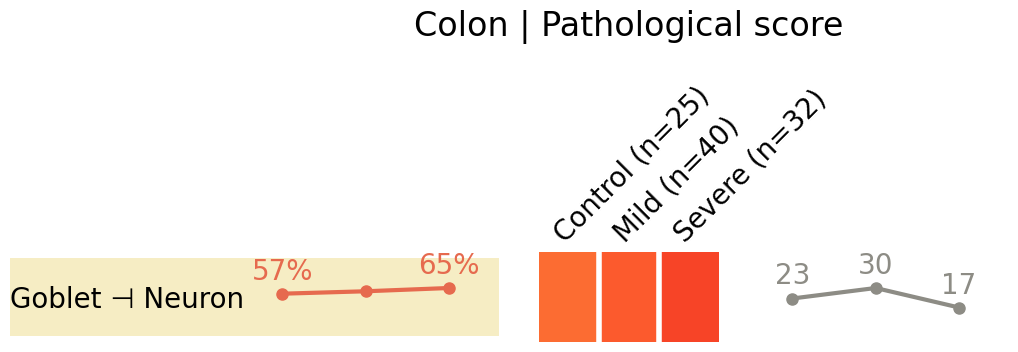

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\stable_rules_FOV\Colon_Cortico_Response.pdf
saved Colon_Cortico_Response_1 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\stable_rules_FOV


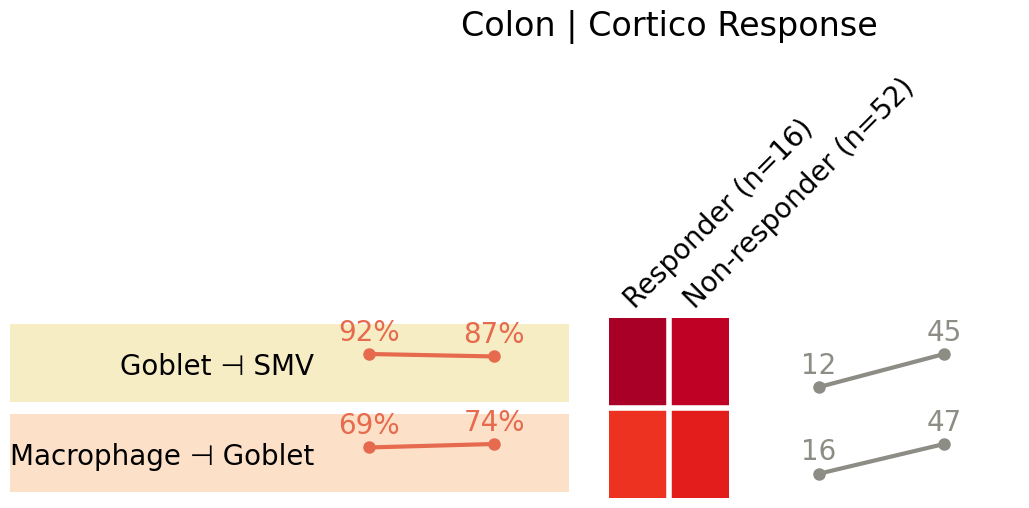

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\stable_rules_FOV\Duodenum_Pathological_score.pdf
saved Duodenum_Pathological_score_1, Duodenum_Pathological_score_2 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\stable_rules_FOV


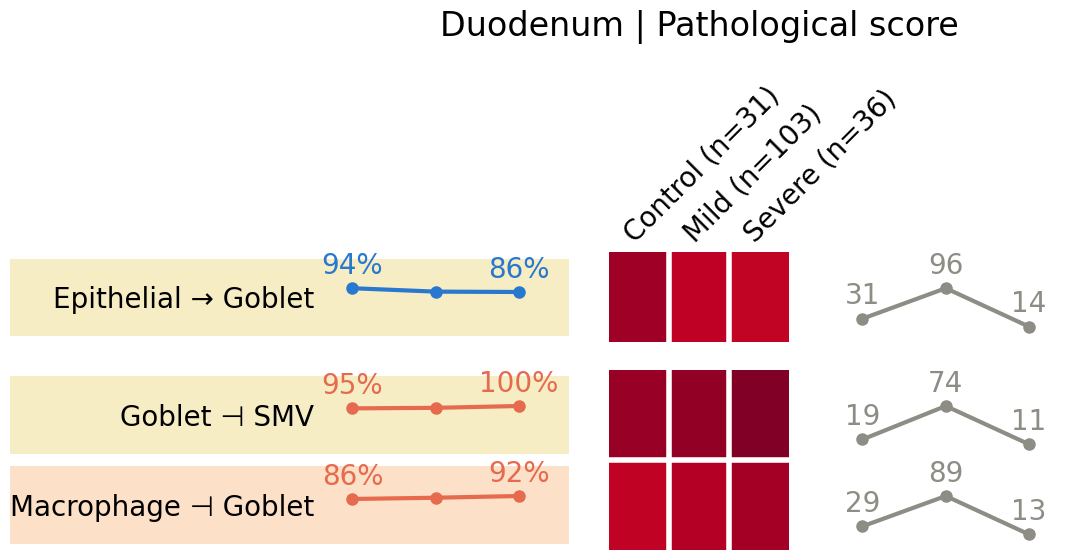

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\stable_rules_FOV\Duodenum_Clinical_score.pdf
saved Duodenum_Clinical_score_1, Duodenum_Clinical_score_2 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\stable_rules_FOV


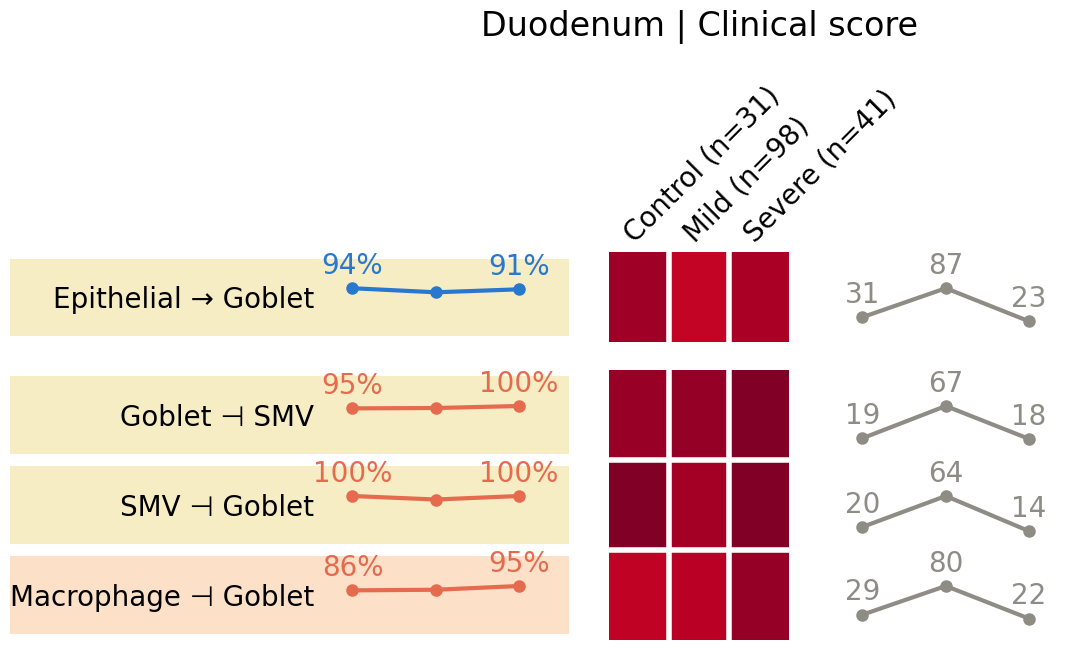

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\stable_rules_FOV\Duodenum_Cortico_Response.pdf
saved Duodenum_Cortico_Response_1, Duodenum_Cortico_Response_2 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\stable_rules_FOV


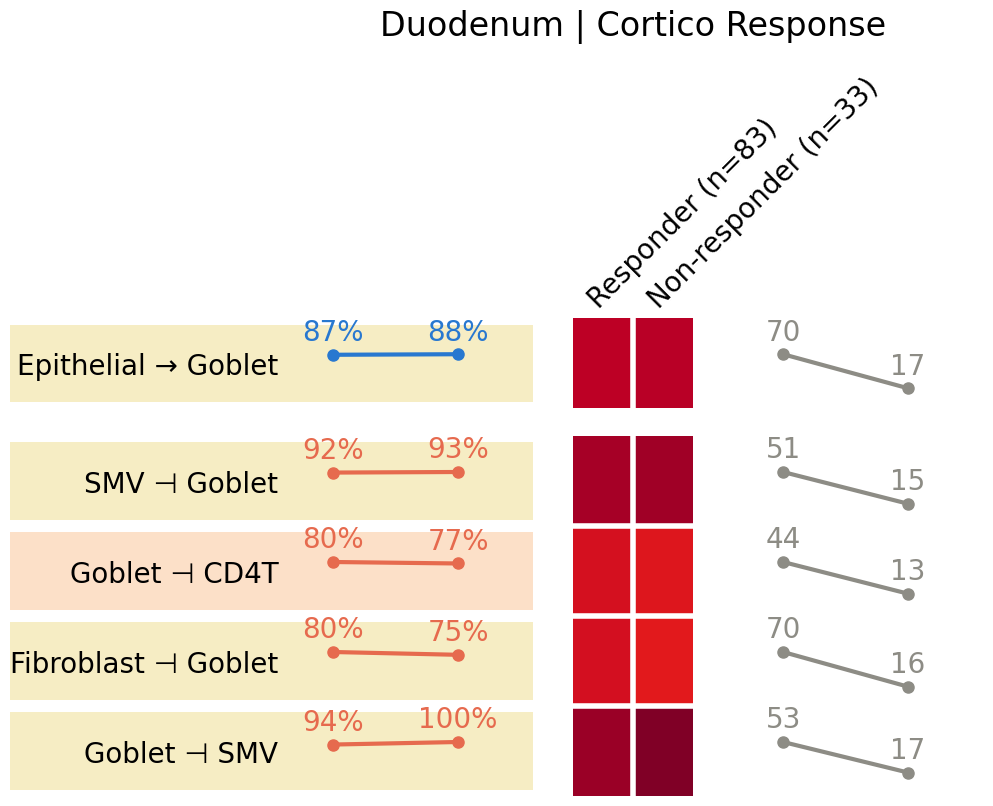

In [9]:
rule_trends(changing=False)